In [1]:
# Import the library to mount Google Drive
from google.colab import drive

import h5py
import torch

In [2]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/HDF5/xrd_uniform_dataset_uni.hdf5"

In [4]:
def print_hdf5_structure(name, obj):
    print(name)

with h5py.File(file_path, "r") as f:
    f.visititems(print_hdf5_structure)

SG_1
SG_1/2theta
SG_1/intensity
SG_10
SG_10/2theta
SG_10/intensity
SG_100
SG_100/2theta
SG_100/intensity
SG_101
SG_101/2theta
SG_101/intensity
SG_102
SG_102/2theta
SG_102/intensity
SG_103
SG_103/2theta
SG_103/intensity
SG_104
SG_104/2theta
SG_104/intensity
SG_105
SG_105/2theta
SG_105/intensity
SG_106
SG_106/2theta
SG_106/intensity
SG_107
SG_107/2theta
SG_107/intensity
SG_108
SG_108/2theta
SG_108/intensity
SG_109
SG_109/2theta
SG_109/intensity
SG_11
SG_11/2theta
SG_11/intensity
SG_110
SG_110/2theta
SG_110/intensity
SG_111
SG_111/2theta
SG_111/intensity
SG_112
SG_112/2theta
SG_112/intensity
SG_113
SG_113/2theta
SG_113/intensity
SG_114
SG_114/2theta
SG_114/intensity
SG_115
SG_115/2theta
SG_115/intensity
SG_116
SG_116/2theta
SG_116/intensity
SG_117
SG_117/2theta
SG_117/intensity
SG_118
SG_118/2theta
SG_118/intensity
SG_119
SG_119/2theta
SG_119/intensity
SG_12
SG_12/2theta
SG_12/intensity
SG_120
SG_120/2theta
SG_120/intensity
SG_121
SG_121/2theta
SG_121/intensity
SG_122
SG_122/2theta
SG_122

In [5]:
with h5py.File(file_path, "r") as f:
    # Load datasets
    theta = f["SG_109/2theta"][:]
    intensity = f["SG_109/intensity"][:]

    print("2theta shape:", theta.shape)
    print("Intensity shape:", intensity.shape)

    # Print first few values
    print("2theta (first 5 values):", theta[:5])
    print("Intensity (first 5 values):", intensity[:5])

2theta shape: (500,)
Intensity shape: (430, 500)
2theta (first 5 values): [20.         20.14028056 20.28056112 20.42084168 20.56112224]
Intensity (first 5 values): [[1.00000000e+02 9.72215854e+01 9.44431708e+01 ... 6.06558080e-03
  6.06558080e-03 6.06558080e-03]
 [1.00000000e+02 9.72215854e+01 9.44431708e+01 ... 6.06558080e-03
  6.06558080e-03 6.06558080e-03]
 [1.00000000e+02 9.72215854e+01 9.44431708e+01 ... 6.06558080e-03
  6.06558080e-03 6.06558080e-03]
 [1.00000000e+02 9.72215854e+01 9.44431708e+01 ... 6.06558080e-03
  6.06558080e-03 6.06558080e-03]
 [1.00000000e+02 9.72215854e+01 9.44431708e+01 ... 6.06558080e-03
  6.06558080e-03 6.06558080e-03]]


In [6]:
with h5py.File(file_path, "r") as f:
    # Load datasets
    theta = f["SG_114/2theta"][:]
    intensity = f["SG_114/intensity"][:]

    print("2theta shape:", theta.shape)
    print("Intensity shape:", intensity.shape)

    # Print first few values
    print("2theta (first 5 values):", theta[:5])
    print("Intensity (first 5 values):", intensity[:5])

2theta shape: (500,)
Intensity shape: (473, 500)
2theta (first 5 values): [20.         20.14028056 20.28056112 20.42084168 20.56112224]
Intensity (first 5 values): [[10.32775589  8.99678685  7.66581781 ...  4.89028651  5.0840493
   5.0840493 ]
 [10.32775589  8.99678685  7.66581781 ...  4.89028651  5.0840493
   5.0840493 ]
 [10.32775589  8.99678685  7.66581781 ...  4.89028651  5.0840493
   5.0840493 ]
 [10.32775589  8.99678685  7.66581781 ...  4.89028651  5.0840493
   5.0840493 ]
 [10.32775589  8.99678685  7.66581781 ...  4.89028651  5.0840493
   5.0840493 ]]


In [7]:
import h5py
import numpy as np

# Storage for all intensity values
all_intensities = []
all_thetas = []

with h5py.File(file_path, "r") as f:
    # Iterate over all top-level groups
    for group_name in f.keys():
        if group_name.startswith("SG_"):  # Ensure it's an SG group
            try:
                theta = f[f"{group_name}/2theta"][:]
                intensity = f[f"{group_name}/intensity"][:]

                # Store for summary
                all_thetas.append(theta)
                all_intensities.append(intensity)

                print(f"Loaded {group_name}: {theta.shape}, {intensity.shape}")
            except KeyError as e:
                print(f"Skipping {group_name}, missing datasets: {e}")

# Convert to numpy arrays
all_thetas = np.concatenate(all_thetas) if all_thetas else np.array([])
all_intensities = np.concatenate(all_intensities) if all_intensities else np.array([])

# Summary statistics
summary = {
    "num_spectra": len(all_intensities),
    "2theta_min": np.min(all_thetas) if all_thetas.size > 0 else None,
    "2theta_max": np.max(all_thetas) if all_thetas.size > 0 else None,
    "intensity_min": np.min(all_intensities) if all_intensities.size > 0 else None,
    "intensity_max": np.max(all_intensities) if all_intensities.size > 0 else None,
    "intensity_mean": np.mean(all_intensities) if all_intensities.size > 0 else None,
    "intensity_std": np.std(all_intensities) if all_intensities.size > 0 else None,
}

# Print summary
for key, value in summary.items():
    print(f"{key}: {value}")


Loaded SG_1: (500,), (487, 500)
Loaded SG_10: (500,), (458, 500)
Loaded SG_100: (500,), (524, 500)
Loaded SG_101: (500,), (441, 500)
Loaded SG_102: (500,), (462, 500)
Loaded SG_103: (500,), (486, 500)
Loaded SG_104: (500,), (497, 500)
Loaded SG_105: (500,), (461, 500)
Loaded SG_106: (500,), (477, 500)
Loaded SG_107: (500,), (451, 500)
Loaded SG_108: (500,), (492, 500)
Loaded SG_109: (500,), (430, 500)
Loaded SG_11: (500,), (498, 500)
Loaded SG_110: (500,), (464, 500)
Loaded SG_111: (500,), (461, 500)
Loaded SG_112: (500,), (469, 500)
Loaded SG_113: (500,), (491, 500)
Loaded SG_114: (500,), (473, 500)
Loaded SG_115: (500,), (469, 500)
Loaded SG_116: (500,), (459, 500)
Loaded SG_117: (500,), (506, 500)
Loaded SG_118: (500,), (486, 500)
Loaded SG_119: (500,), (497, 500)
Loaded SG_12: (500,), (462, 500)
Loaded SG_120: (500,), (473, 500)
Loaded SG_121: (500,), (480, 500)
Loaded SG_122: (500,), (477, 500)
Loaded SG_123: (500,), (473, 500)
Loaded SG_124: (500,), (470, 500)
Loaded SG_125: (500

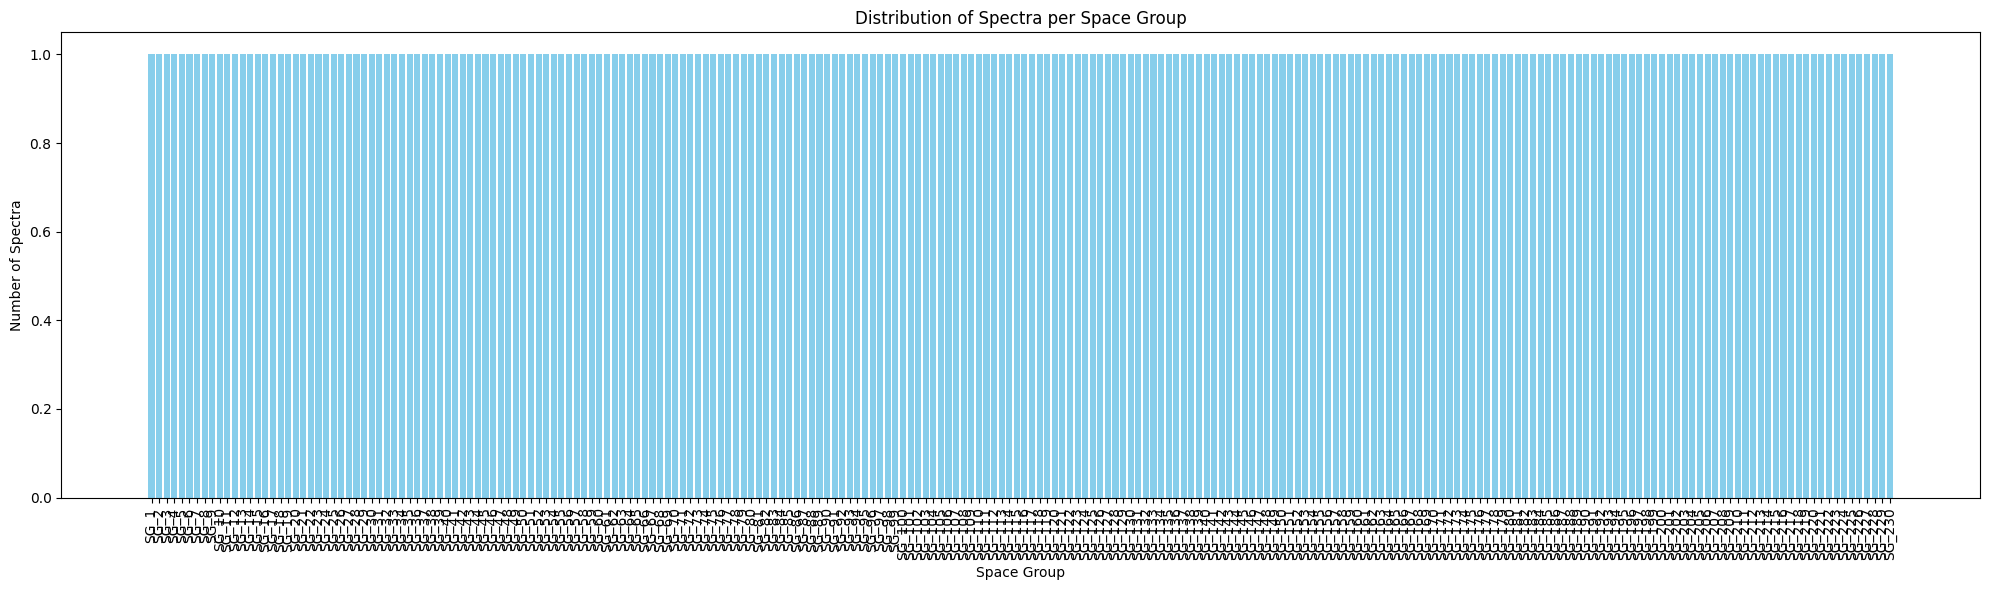

In [8]:
import h5py
import matplotlib.pyplot as plt
from collections import defaultdict

# Dictionary to store count per SG group
sg_counts = defaultdict(int)

with h5py.File(file_path, "r") as f:
    for group_name in f.keys():
        if group_name.startswith("SG_"):
            try:
                # Just check that intensity data exists
                intensity = f[f"{group_name}/intensity"][:]
                sg_counts[group_name] += 1
            except KeyError:
                continue

# Sort space groups numerically
sorted_sg = sorted(sg_counts.items(), key=lambda x: int(x[0].split('_')[1]))

# Unpack into x and y
sg_labels, counts = zip(*sorted_sg)

# Plotting
plt.figure(figsize=(20, 6))
plt.bar(sg_labels, counts, color='skyblue')
plt.xticks(rotation=90)
plt.xlabel("Space Group")
plt.ylabel("Number of Spectra")
plt.title("Distribution of Spectra per Space Group")
plt.tight_layout()
plt.show()


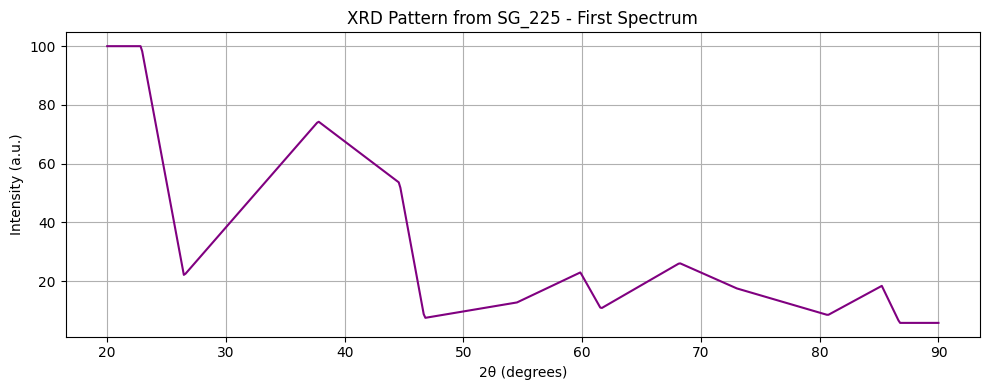

In [9]:
import h5py
import matplotlib.pyplot as plt

#file_path = "your_file.h5"
sg = "SG_225"

with h5py.File(file_path, "r") as f:
    twotheta = f[f"{sg}/2theta"][:]
    intensity = f[f"{sg}/intensity"][:]

# Plot only the first spectrum
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity[0], color='purple')
plt.title(f"XRD Pattern from {sg} - First Spectrum")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()

